# State of the art: what the literature measured, and what the toolkits leave out

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02 to 06 of this topic (the measurements the literature is compared with)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- name the three published simulation studies on the size and power of validation tests (BCBS Working Paper 14, Yurdakul and Naranjo, Demler et al.), say what each measured, and read how the engine's reruns compare with them cell by cell;
- check each verdict the literature gives about a test (the binomial test under correlation, the normal test, the PSI rules of thumb, DeLong on nested models, the Hosmer-Lemeshow degrees of freedom) against the measurement in the committed artifacts, and say where the verdict holds and where it needs a qualification;
- say what the validation toolkits of the product's research cover and what they leave out: the ECB tests, and any measured size or power.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the committed artifacts of case C22 (validating the validator), baked with known-truth generators of `riskvalidation.generators` (licence MIT, class `generated`). Three of them carry, in `outputs.golden`, a published simulation study rerun cell by cell: the published rate of each cell, the rate the engine measured and the standardised difference. The published rates are numbers quoted from the papers (derived-only).

- **Files read:** `data/derived/C22/clustering.json` (BCBS Working Paper 14, Tables 7 and 8, 144 cells) and its simulations; `drift.json` (Yurdakul and Naranjo, Table 4, 54 cells); `leakage.json` (Demler et al., one cell); and `null.json` for the Hosmer-Lemeshow rows.
- **The literature itself** is cited from the research dossiers of the product (`wip/contraste/12-u3-size-power-and-generators` sections 2 to 6, and `06-model-risk-management-and-validation` sections C and D, in the CAOS_MANAGE records), which read each paper on 2026-10-04 and 2026-10-05. Direct quotes below are verbatim from those readings, with page numbers where the dossier records them.

The next cell loads the four artifacts and prints the engine version that baked them.

In [2]:
# Load the four artifacts of the comparison and print the engine version that baked them
LANG = "en"
ROOT = Path("../../..").resolve()
files = ("clustering", "drift", "leakage", "null")
artifacts = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in files}
rows = {name: {row["key"]: row for row in art["outputs"]["simulations"]} for name, art in artifacts.items()}
clustering, drift, leakage, null = (artifacts[name] for name in files)

for name in files:
    print(f"{name:11s} baked by riskvalidation {artifacts[name]['provenance']['riskvalidation_version']} | {len(rows[name]):2d} simulations")
print("installed:", rv.__version__)

clustering  baked by riskvalidation 0.4.3 | 48 simulations
drift       baked by riskvalidation 0.4.3 | 30 simulations
leakage     baked by riskvalidation 0.4.3 | 14 simulations
null        baked by riskvalidation 0.4.3 | 28 simulations
installed: 0.9.0


## Method

A rerun of a published simulation study is compared with the paper cell by cell. The paper's rate $r_\text{pub}$ comes from $n_\text{pub}$ runs and ours, $\hat r$, from $n$ runs; both estimate one true rate, so their difference has variance $\bar r(1-\bar r)(1/n + 1/n_\text{pub})$ at the pooled rate $\bar r$, and a cell agrees when the standardised difference satisfies $|z| \le 3.29$ (two-sided 0.1%, since the study makes many comparisons). The engine's `agrees_with_published` computes it (Morris, White and Crowther, 2019, for the Monte Carlo error of each rate).

This notebook goes beyond counting agreements: for each verdict the literature gives about a test, it evaluates the verdict on the committed measurements and says whether it holds, holds with a qualification, or does not hold. The first step tallies the published cells of the three studies.

### Step 1: three published studies, every cell recomputed

The next cell recomputes the standardised difference of every published cell of the three studies from the committed measured rate and the published one, counts the agreements, and draws the measured rate against the published one for all cells. Cells near the diagonal agree; the cell that does not is marked.

BCBS WP14 Tables 7 and 8: the normal and traffic-lights tests          |  25000 runs | 143 of 144 agree | committed 143 | mean z -0.112
Yurdakul and Naranjo (2020) Table 4: the PSI's rules and benchmark     |  10000 runs |  50 of  54 agree | committed 50 | mean z +0.666
Demler, Pencina and D'Agostino (2012): DeLong on nested models         |   1000 runs |   1 of   1 agree | committed 1 | mean z +0.578
all cells: 194 of 199


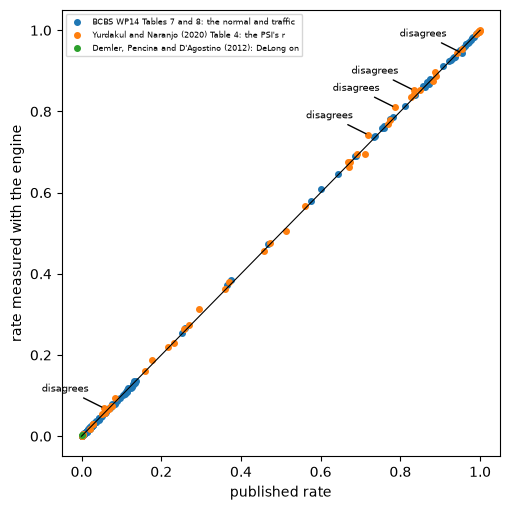

In [3]:
# Recompute every published cell of the three studies with agrees_with_published and draw measured against published
from riskvalidation.harness import Rate, agrees_with_published

fig, ax = plt.subplots(figsize=(5.2, 5.2))
total_cells = total_agree = 0
for index, name in enumerate(("clustering", "drift", "leakage")):
    study = artifacts[name]["outputs"]["golden"][0]
    n_runs = study["runs"]
    published, measured, agree, z_values = [], [], 0, []
    for cell in study["cells"]:
        ok, z = agrees_with_published(Rate(round(cell["measured"] * n_runs), n_runs), cell["published"], study["runs_published"])
        agree += ok
        z_values.append(z)
        published.append(cell["published"])
        measured.append(cell["measured"])
        if not ok:
            ax.annotate("disagrees", (cell["published"], cell["measured"]), fontsize=7, xytext=(-45, 12), textcoords="offset points", arrowprops={"arrowstyle": "-"})
    ax.plot(published, measured, "o", markersize=4, color=f"C{index}", label=study["title"][LANG][:48])
    total_cells += len(study["cells"])
    total_agree += agree
    print(f"{study['title'][LANG][:70]:70s} | {study['runs_published']:6d} runs | {agree:3d} of {len(study['cells']):3d} agree | committed {study['agree']} | mean z {np.mean(z_values):+.3f}")
print("all cells:", total_agree, "of", total_cells)
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("published rate")
ax.set_ylabel("rate measured with the engine")
ax.legend(fontsize=6, loc="upper left")
fig.tight_layout()
plt.show()

## State of the art

### BCBS Working Paper 14 (2005): the calibration tests

The Basel Committee's Working Paper 14 (Studies on the validation of internal rating systems, revised, May 2005) evaluates the calibration tests and runs a simulation study of two of them. Its verdicts (pages 41 to 42):

- **Binomial test:** "Examples in the appendix show that the true type I error (i.e. the probability to reject erroneously the hypothesis of an adequate PD forecast) can be much larger than the nominal level of the test if default events are correlated." Taking dependence into account "yield[s] tests of rather moderate power, even for low levels of correlation".
- **Normal test:** "Simulation studies show that the quality of the normal approximation is moderate but exhibits a conservative bias. As a consequence, the true Type I error tends to be lower than the nominal level of the test".
- **Conclusion:** "at present no really powerful tests of adequate calibration are currently available. Due to the correlation effects that have to be respected there even seems to be no way to develop such tests."

The appendix prints critical values of the binomial test for a PD of 1%, 1,000 obligors and a confidence of 99% (Example 3): 19 defaults when the defaults are independent, and 35, 49, 63 and 77 when the asset correlation is 5%, 10%, 15% and 20% (dossier 12, section 2.2). The first check recomputes them with the engine and the true size they imply.

### Step 2: the binomial test under correlation

`critical_count` finds the smallest default count at which a registered test rejects. With `pd.binomial` at the 1% level it gives the independent critical value, and with `pd.binomial_vasicek` at an assumed correlation it gives the critical value of the corrected test. `rejection_probability` then gives the true size of the independent test (the 99% test of the paper) when the defaults follow that correlation.

In [4]:
# Critical counts of the independent and the Vasicek-corrected binomial test at 99%, and the true size of the independent test under correlation
from riskvalidation.harness import critical_count, rejection_probability

print(f"{'asset correlation':>18s} {'k* corrected':>13s} {'k* independent':>15s} {'true size of the independent test':>38s}")
independent_k = critical_count("pd.binomial", 1000, 0.01, 0.01)
print(f"{0.0:18.2f} {independent_k:13d} {independent_k:15d} {rejection_probability('pd.binomial', 1000, 0.01, 0.01)['probability']:38.4f}")
for rho in (0.05, 0.10, 0.15, 0.20):
    corrected_k = critical_count("pd.binomial_vasicek", 1000, 0.01, 0.01, rho=rho)
    size = rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=rho)["probability"]
    print(f"{rho:18.2f} {corrected_k:13d} {independent_k:15d} {size:38.4f}")

 asset correlation  k* corrected  k* independent      true size of the independent test
              0.00            19              19                                 0.0069
              0.05            35              19                                 0.1113
              0.10            49              19                                 0.1441
              0.15            63              19                                 0.1539
              0.20            77              19                                 0.1549


### Step 3: the verdict on the normal test

WP14 says the normal test "exhibits a conservative bias", with a true type I error that "tends to be lower than the nominal level". The paper's own Table 7 reports the type I error at 5% in eight scenarios, four with independent years (`I_`) and four with dependence (`DC_`, `DV_`). The next cell reads the published rates at 5% from the artifact, counts how many are above 5% in each group, and prints the size the engine measured in the clustering ladder, where the factor correlation across years is 0.2 whenever the asset correlation is positive.

In [5]:
# Count the published type I errors of the normal test above 5% by group and print the measured size along the clustering ladder
study = clustering["outputs"]["golden"][0]
published_normal = {c["row"]: c["published"] for c in study["cells"] if c["table"] == "Table 7" and c["column"] == "0.05" and "normal" in c["row"]}
for group, prefix in (("independent years", "I_"), ("dependent years", "D")):
    chosen = {name: rate for name, rate in published_normal.items() if name.startswith(prefix)}
    above = sum(rate > 0.05 for rate in chosen.values())
    print(f"{group:20s} published rates at 5%: {sorted(chosen.values())} | above 5%: {above} of {len(chosen)}")

ladder = clustering["outputs"]["ladder"]["values"]
measured = [rows["clustering"][f"pd.normal_multiperiod@rho{rho:g}"]["rates"]["p<0.05"]["rate"] for rho in ladder]
print("measured size, by asset correlation", {rho: round(float(rate), 4) for rho, rate in zip(ladder, measured)})

independent years    published rates at 5%: [0.059, 0.059, 0.077, 0.081] | above 5%: 4 of 4
dependent years      published rates at 5%: [0.037, 0.049, 0.062, 0.07] | above 5%: 2 of 4
measured size, by asset correlation {0.0: 0.082, 0.02: 0.0905, 0.05: 0.074, 0.1: 0.0515, 0.15: 0.0455, 0.2: 0.035}


### Step 4: "no really powerful tests"

The paper's conclusion is about calibration tests under correlated defaults. The exact rejection probability of the Vasicek-corrected binomial test, which is the paper's own answer to correlation, can be computed when the true correlation equals the assumed one. The next cell computes its power at 5%, for 1,000 obligors at a PD of 1%, as the true PD rises to 1.25, 1.5, 2 and 3 times the PD applied, for an asset correlation of 5% (low) and 12%, and prints the power of the uncorrected binomial test beside it together with its size at $k = 1$, which tells whether that power is bought with false alarms.

In [6]:
# Exact power of the corrected and the uncorrected binomial test under correlated defaults, n = 1000, PD = 1%
factors = (1.0, 1.25, 1.5, 2.0, 3.0)
print(f"{'correlation':>11s} {'test':>13s} " + " ".join(f"{'k = ' + str(k):>8s}" for k in factors) + f"   ({'power at 5%; k = 1 is the size'})")
for rho in (0.05, 0.12):
    corrected = [rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, pd_true=0.01 * k, rho_true=rho, rho=rho)["probability"] for k in factors]
    plain = [rejection_probability("pd.binomial", 1000, 0.01, 0.05, pd_true=0.01 * k, rho_true=rho)["probability"] for k in factors]
    print(f"{rho:11.2f} {'corrected':>13s} " + " ".join(f"{p:8.3f}" for p in corrected))
    print(f"{rho:11.2f} {'uncorrected':>13s} " + " ".join(f"{p:8.3f}" for p in plain))

correlation          test  k = 1.0 k = 1.25  k = 1.5  k = 2.0  k = 3.0   (power at 5%; k = 1 is the size)
       0.05     corrected    0.043    0.087    0.145    0.284    0.561
       0.05   uncorrected    0.178    0.282    0.388    0.576    0.816
       0.12     corrected    0.050    0.080    0.114    0.190    0.349
       0.12   uncorrected    0.198    0.270    0.340    0.465    0.653


### Yurdakul and Naranjo (2020): the PSI

Yurdakul and Naranjo (Statistical properties of the population stability index, Journal of Risk Model Validation 14(4)) start from the observation that the PSI bands of 0.10 and 0.25 are "used without reference to statistical type I or type II error rates". They derive the sampling distribution of the index (their Theorem 3.3), propose the benchmark $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$ and report a simulation (Table 4) with 10,000 runs. Their reading: "the type I error rate for PSI > 0.10 is too large, except when both sample sizes exceed 400. In contrast, the type I error rate for PSI > 0.25 is too small when both sample sizes exceed 200, so the test is too conservative. The chi-square benchmark maintains a reasonable type I error, close to $\alpha$ = 0.05 [...] the tests PSI > 0.10 and PSI > 0.25 have powers that actually decrease with sample size."

### Step 5: the four findings, on Table 4

The artifact's cells let each finding be read. The next cell takes the rows with equal samples ($m = n$ = 100, 200, 400) and prints, for the no-shift columns (type I error) and the quarter-standard-deviation columns (power), the published and the measured rate of the two rules and the benchmark, then checks the direction of each finding on the measured rates.

In [7]:
# Print the published and measured rates of the two rules and the benchmark for equal samples and check the direction of each finding
from functools import reduce

GLOSSARY = ()
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)
yn = drift["outputs"]["golden"][0]["cells"]
sizes = ("m 100, n 100", "m 200, n 200", "m 400, n 400")
columns = ("PSI > 0.10", "PSI > 0.25", "chi-square")
measured = {}
for shift in ("0", "0.25"):
    print("shift", shift, "SD", "(published / measured)")
    for size in sizes:
        cells = {c["column"]: c for c in yn if c["row"] == size}
        parts = []
        for column in columns:
            c = cells[f"shift {shift} SD, {column}"]
            measured[(shift, size, column)] = c["measured"]
            parts.append(f"{c['published']:.3f} / {c['measured']:.4f}")
        print(f"  {size:14s} " + " | ".join(f"{gloss(col)}: {part}" for col, part in zip(columns, parts)))

rule10 = [measured[("0", s, "PSI > 0.10")] for s in sizes]
rule25 = [measured[("0", s, "PSI > 0.25")] for s in sizes]
chi = [measured[("0", s, "chi-square")] for s in sizes]
print("type I error of the 0.10 rule falls below 5% only at 400:", [round(r, 3) for r in rule10], [r < 0.05 for r in rule10])
print("type I error of the 0.25 rule is far below 5% above 200:", [round(r, 4) for r in rule25])
print("chi-square benchmark stays between", round(min(chi), 4), "and", round(max(chi), 4))
for column in columns[:2]:
    power = [measured[("0.25", s, column)] for s in sizes]
    print(f"{'power of'} {column} {'with the sample size:'} {[round(p, 3) for p in power]} | {'decreases:'} {power[0] > power[1] > power[2]}")
power_chi = [measured[("0.25", s, "chi-square")] for s in sizes]
print("power of the chi-square benchmark with the sample size:", [round(p, 3) for p in power_chi], "|", "increases:", power_chi[0] < power_chi[1] < power_chi[2])

shift 0 SD (published / measured)
  m 100, n 100   PSI > 0.10: 0.849 / 0.8525 | PSI > 0.25: 0.233 / 0.2284 | chi-square: 0.076 / 0.0753
  m 200, n 200   PSI > 0.10: 0.369 / 0.3807 | PSI > 0.25: 0.004 / 0.0043 | chi-square: 0.057 / 0.0688
  m 400, n 400   PSI > 0.10: 0.020 / 0.0186 | PSI > 0.25: 0.000 / 0.0000 | chi-square: 0.051 / 0.0555
shift 0.25 SD (published / measured)
  m 100, n 100   PSI > 0.10: 0.943 / 0.9429 | PSI > 0.25: 0.459 / 0.4570 | chi-square: 0.218 / 0.2198
  m 200, n 200   PSI > 0.10: 0.775 / 0.7787 | PSI > 0.25: 0.085 / 0.0934 | chi-square: 0.360 / 0.3623
  m 400, n 400   PSI > 0.10: 0.513 / 0.5064 | PSI > 0.25: 0.004 / 0.0032 | chi-square: 0.671 / 0.6638
type I error of the 0.10 rule falls below 5% only at 400: [0.853, 0.381, 0.019] [False, False, True]
type I error of the 0.25 rule is far below 5% above 200: [0.2284, 0.0043, 0.0]
chi-square benchmark stays between 0.0555 and 0.0753
power of PSI > 0.10 with the sample size: [0.943, 0.779, 0.506] | decreases: True
po

### Demler, Pencina and D'Agostino (2012): DeLong on nested models

Demler et al. (Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23)) show that the DeLong test, derived for models with known parameters, is conservative when it compares two models fitted on the same data and the larger one adds a predictor with no effect. Their simulation, on Framingham-like data with 1,000 repetitions, found: "the significance level for the F-test is close to the nominal 0.05 level, whereas it is 0.001 for the DeLong test."

### Step 6: the one published cell

`leakage.json` holds that cell: the published rate (0.001), the engine's rate over the same design and the standardised difference. The next cell prints it, with the rate the engine measured for the non-nested comparison on an independent sample, where the paper finds no problem.

In [8]:
# Print the published Demler cell, the engine's rate and the non-nested comparison
study = leakage["outputs"]["golden"][0]
cell = study["cells"][0]
print(gloss(cell["table"]), "|", gloss(cell["row"]), "|", "level", cell["column"], "|", "published", cell["published"], "|", "measured", cell["measured"], "| z", round(cell["z"], 2), "|", "agrees:", cell["agrees"])
non_nested = rows["leakage"]["disc.delong@non-nested"]["rates"]["p<0.05"]
print("non-nested scores on an independent sample:", round(non_nested["rate"], 4), "(SE", round(non_nested["se"], 4), ")")

section 2.3 | DeLong, nested | level 0.05 | published 0.001 | measured 0.002 | z 0.58 | agrees: True
non-nested scores on an independent sample: 0.0525 (SE 0.005 )


### Hosmer and Lemeshow (1980): the degrees of freedom

The Hosmer-Lemeshow statistic groups obligors by predicted risk. Its original reference distribution is $\chi^2_{G-2}$, for a model fitted on the same data. BCBS WP14 argues for given PDs that each group's standardised gap is asymptotically an independent $\chi^2_1$, so that the statistic over $G$ groups is $\chi^2_G$ (page 60, for its test over grades). The literature the dossier read gives no explicit rule for validation samples ("degrees of freedom stated from the standard result, paper not re-read", dossier 06), and tools are not consistent about it.

### Step 7: what each choice does on a validation sample

The next cell computes, with SciPy, the size a $G-2$ threshold gives to a $\chi^2_G$ statistic and sets it beside the two committed rows of the `null` family: the engine with $G$ degrees of freedom (the default for given PDs) and with $G-2$ (`fitted=True`).

In [9]:
# Size of a G-2 threshold on a chi-square(G) statistic beside the committed Hosmer-Lemeshow rows
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    tail = stats.chi2.sf(stats.chi2.ppf(1 - alpha, 8), 10)
    given = rows["null"]["pd.hosmer_lemeshow@null"]["rates"][rule]
    fitted = rows["null"]["pd.hosmer_lemeshow@fitted"]["rates"][rule]
    print(f"level {alpha:.2f} | chi-square(10) beyond the chi-square(8) threshold {tail:.4f} | G-2: {fitted['rate']:.4f} ± {fitted['se']:.4f} | G: {given['rate']:.4f} ± {given['se']:.4f}")

level 0.05 | chi-square(10) beyond the chi-square(8) threshold 0.1146 | G-2: 0.1098 ± 0.0049 | G: 0.0460 ± 0.0033
level 0.01 | chi-square(10) beyond the chi-square(8) threshold 0.0284 | G-2: 0.0338 ± 0.0029 | G: 0.0097 ± 0.0016


### The ECB tests and the validation toolkits

The ECB's instructions for reporting validation results (2019) define the statistics and the p-values of the tests the engine implements (the Jeffreys test, the AUC against the initial AUC, the migration tests, the concentration test). The product's research (dossier 06, section A.3) verified by full-text search that the document fixes statistics and p-values and sets no pass or fail thresholds, which are the institution's responsibility.

The toolkits the research surveyed on 2026-10-04 (dossier 06, section D, through the GitHub and PyPI interfaces) offer, among others:

| Toolkit | What its documentation lists | Licence |
|---|---|---|
| PiML-Toolbox | outcome tests: accuracy, explainability, fairness, weak spots, overfit, reliability, robustness, resilience; superseded by MoDeVa | Apache-2.0 (MoDeVa proprietary) |
| ValidMind | data and model validation tests, including PSI, KS, Gini and calibration curves, and drift | AGPL-3.0 or commercial |
| BBVA mercury-robust and mercury-monitoring | drift, label leaking, schema and cohort tests | Apache-2.0 |
| ING popmon | drift: KS, chi-squared, Jensen-Shannon, PSI; traffic lights on pulls of 4 and 7 standard deviations | MIT |
| Evidently | drift: KS, chi-squared, z-test, Wasserstein, Jensen-Shannon, PSI, KL; data quality; model quality | Apache-2.0 |
| NannyML | label-free performance estimation, univariate and multivariate drift | Apache-2.0 |
| deepchecks | data integrity, train-test validation and model evaluation suites | AGPL-3.0 |
| alibi-detect | drift: KS, MMD, LSDD, chi-square, classifier-based; outliers | BSL 1.1 |

The dossier records (lines 1117 to 1121) that no toolkit found implements the ECB Jeffreys, MWB, migration z-tests, HHI-CV test or gAUC exactly as specified. Its catalogues list tests, thresholds and traffic lights; the dossier recorded no measured size or power for them in the READMEs and documentation it read. That is a statement about what the survey found, and UNVERIFIED beyond it: the survey did not run the toolkits or read their source.

## Results

- **The engine reruns the three published studies: 194 of 199 cells agree.** BCBS Working Paper 14 gives 143 of 144 (mean standardised difference -0.11, so the engine sits slightly under the paper), Yurdakul and Naranjo 50 of 54 (+0.67, slightly above) and Demler et al. 1 of 1. The five cells that do not agree are the one traffic-lights cell of Table 8 (notebook 04) and the four cells of Table 4 (notebook 05). The figure shows every cell on or near the diagonal, with the one cell far from it marked.
- **The binomial verdict holds, and the paper's critical values are reproduced.** The engine's corrected binomial test gives critical counts of 35, 49, 63 and 77 defaults at asset correlations of 5%, 10%, 15% and 20%, against 19 for the independent test: the values the paper prints for its Example 3. The independent 99% test, which should reject 1% of the time, has a true size of 0.69% without correlation and 11.1%, 14.4%, 15.4% and 15.5% with it. "Much larger than the nominal level" is exact.
- **The normal-test verdict needs a qualification.** WP14 says the true type I error "tends to be lower than the nominal level". Its own Table 7 shows the normal test above 5% in all four independent scenarios (5.9% to 8.1%) and in two of four dependent ones, and the engine measures 8.2% with independent years, 9.1% at an asset correlation of 2% and 7.4% at 5%. The size reaches the nominal level only with strong dependence (5.2% at 10%, 4.6% at 15%, 3.5% at 20%). The conservative bias is real for strongly correlated years; for a five-year series the test over-rejects, which notebook 02 traces to a $t$ statistic with four degrees of freedom.
- **"No really powerful tests" holds for correlated defaults, with numbers.** The Vasicek-corrected binomial test, with the correct correlation, has a power of 8.7% when the PD is 25% too low and 14.5% when it is 50% too low at a correlation of 5%, and 56.1% when it is three times too low; at 12% the figures are 8.0%, 11.4% and 34.9%. The uncorrected test has more power (28.2% to 81.6% at 5%) only because its size under that correlation is 17.8%: the power is bought with false alarms. With independent defaults the picture changes (notebook 03: 80% power at a PD 26% too low). The paper's pessimism is about clustering, and clustering is what costs the power.
- **All four Yurdakul and Naranjo findings reproduce in direction.** The 0.10 rule has a type I error of 85.3%, 38.1% and 1.9% at 100, 200 and 400 per sample, below 5% only at 400; the 0.25 rule 22.8%, 0.4% and 0.0%; the chi-square benchmark stays between 5.6% and 7.5%. The power of the two rules falls with the sample size (94.3%, 77.9%, 50.6% and 45.7%, 9.3%, 0.3% at a shift of a quarter standard deviation) while the benchmark's rises (22.0%, 36.2%, 66.4%). The offset is stated: the chi-square cell at 200 per sample, 6.9% against the printed 5.7%, is one of the four cells that disagree.
- **Demler et al. reproduce.** The nested DeLong test rejected 2 of 1,000, against the 0.001 they report (z = 0.58); on non-nested scores of equal AUC and an independent sample it rejects 5.25% (SE 0.50 points), which is the case where the paper finds no problem.
- **The Hosmer-Lemeshow degrees of freedom are not settled by the literature the research read, and the measurement settles them for the engine.** A $G-2$ threshold on a $\chi^2_G$ statistic would reject 11.5% at 5% and 2.8% at 1%; the engine with $G-2$ measures 11.0% and 3.4%, and with $G$ degrees of freedom 4.6% and 1.0%.
- **The toolkits leave out the ECB tests and any measured error rate, as far as the survey went.** The eight toolkits surveyed list drift, performance and robustness tests, some with default thresholds or traffic lights, and the dossier records none that implements the ECB's Jeffreys, MWB, migration z-tests, HHI-CV and gAUC tests as specified, and none that publishes a measured size or power. That is a statement about a survey of documentation made on 2026-10-04, not about the tools' code.

What this notebook does not show: the verdicts of studies outside the three simulations and the dossier's reading (for example the later literature on the Hosmer-Lemeshow groups), or how the toolkits behave when run. Whether the measurement in notebook 08 goes beyond this state of the art is its own question.

## Summary

- Three published simulation studies on the size and power of validation tests exist in the research (BCBS Working Paper 14, Yurdakul and Naranjo, Demler et al.), and the engine reruns 194 of their 199 cells within Monte Carlo error.
- WP14's verdict on the binomial test holds exactly; its verdict that the normal test is conservative holds only under strong dependence; its pessimism about power holds for correlated defaults, with the numbers shown.
- Yurdakul and Naranjo's four findings on the PSI reproduce in direction, with a stated offset on four cells; Demler et al.'s 0.001 reproduces as 2 in 1,000.
- The literature the research read does not settle the Hosmer-Lemeshow degrees of freedom for given PDs; the measurement does, in favour of $G$.
- The toolkits surveyed list tests and thresholds, implement none of the ECB tests as specified, and record no measured size or power, as far as the survey went.

**What to try next.** Change the asset correlation in step 4 to 0.20 and watch the power of the corrected test at the same factors; then read notebook 08, which sets the whole measurement against this state of the art.

## References

- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the verdicts on the calibration tests (pages 41 to 42), the appendix examples on the binomial test, and the simulation of the normal and traffic-lights tests (pages 61 to 67). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- The product's research dossiers (CAOS_MANAGE records, `wip/contraste/`): 06 (model risk management and validation, sections A, C and D) and 12 (size, power and generators, sections 1 to 6), read on 2026-10-04 and 2026-10-05; and this repository's `docs/design/features/c22-validator/requirements.md`.